# 6 — Trade-off: AST original, Jacobiana, Shao–Wu e Heaps

## Resumo

Comparamos quatro geradores completos, com 5.000 mecanismos independentes e uma trajetória por mecanismo. Mantemos horizontes 96/192/384, explosão operacional acima de 100 ou valor não finito, e cauda de baixa amplitude com 24 valores em [-0.15,0.15]. Medimos proporções, intervalos de Wilson e velocidade por fase. Os resultados são recalculados nesta execução.

## 1. Desenho

| Método | Família | Inicialização | Inovação |
|---|---|---|---|
| original | AST de somas/produtos | Uniforme [-1,1] | Gaussiana |
| jacobian | AST certificada em caixa | Uniforme no domínio | Uniforme limitada |
| shao-wu | AST com TANH e limites globais | Burn-in com erro L2 <= 1e-4 | Gaussiana |
| heaps-var | VAR(p) simétrico | Normal estacionária conjunta | Gaussiana |

Todos usam uma variável e inovação com desvio 0.05. Isso mantém a dimensão compatível com o certificado atual da Jacobiana. Os notebooks específicos demonstram duas variáveis. As famílias e distribuições diferem; a comparação mantém número de mecanismos, dimensões, horizontes e variância do ruído.

[Shao–Wu, Teorema 5.1](https://arxiv.org/pdf/math/0611029#page=11); [Heaps, apêndice](https://arxiv.org/pdf/2004.09455#page=11). As escolhas de amostragem e burn-in são adaptações do projeto.

In [1]:
from __future__ import annotations
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "src" / "tsfmxai").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tsfmxai.generators import (
    RandomTreeConfig, ContractionTreeConfig, ShaoWuConfig, HeapsVARConfig,
    sample_random_mechanisms, sample_contractive_mechanisms,
    sample_shao_wu_mechanism, sample_shao_wu_mechanisms, sample_shao_wu_trajectories,
    sample_heaps_var_mechanism, sample_heaps_var_mechanisms, sample_heaps_var_trajectories,
    evaluate_expression_with_gradient, evaluate_bound_expression, var_companion_matrix,
    global_expression_bounds,
)
from tsfmxai.evaluation import StabilityDiagnosticConfig, wilson_interval
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
BLAS_CONTROLLER = threadpool_limits(limits=1)
ROOT_SEED = 20261001
HORIZONS = (96, 192, 384)
INNOVATION_STD = .05
DIAGNOSTIC_CONFIG = StabilityDiagnosticConfig(HORIZONS, 100., 3 * INNOVATION_STD, 24)
BASE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.80,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
SHAO_CONFIG = ShaoWuConfig(tree_config=BASE_CONFIG, innovation_std=INNOVATION_STD,
                           target_gain=.8, burn_in_tolerance=1e-4)
HEAPS_CONFIG = HeapsVARConfig(num_series=1, minimum_order=1, maximum_order=12,
                             unconstrained_std=.45, innovation_std=INNOVATION_STD)

EXPERIMENT_ID = "abstract_syntax_tree_006_four_current_methods"
NOTEBOOK_PATH = "experiments/abstract_syntax_tree/6_stability_methods_tradeoff.ipynb"
RESEARCH_QUESTION = "Qual o trade-off entre falhas operacionais, baixa amplitude e custo dos quatro geradores?"
HYPOTHESIS = "Certificados reduzem falhas nas famílias admitidas, com custo de construção e inicialização."
SAMPLE_COUNT = 5000
METHOD_ORDER = ["original", "jacobian", "shao-wu", "heaps-var"]
CONTRACTION_CONFIG = ContractionTreeConfig(
    tree_config=replace(BASE_CONFIG, coefficient_gate_lags=True),
    domain_radius=1., innovation_bound=np.sqrt(3.)*INNOVATION_STD,
    lag_weight_growth=1.25, target_lipschitz=.90, scale_safety_factor=.95,
)
configuration = {
    "root_seed": ROOT_SEED, "count_per_method": SAMPLE_COUNT, "num_series": 1,
    "diagnostics": asdict(DIAGNOSTIC_CONFIG), "original": asdict(BASE_CONFIG),
    "jacobian": asdict(CONTRACTION_CONFIG), "shao-wu": asdict(SHAO_CONFIG),
    "heaps-var": asdict(HEAPS_CONFIG), "blas_threads": 1, "trajectories_per_mechanism": 1,
    "future_noise": "same Gaussian draws per index for original/Shao-Wu/Heaps; uniform for Jacobian",
    "initialization": {"original": "uniform", "jacobian": "uniform inside D",
                       "shao-wu": "burn-in with L2 error <= 1e-4", "heaps-var": "joint invariant Gaussian"},
}
pd.set_option("display.max_columns", None)
print(json.dumps(configuration, indent=2))


{
  "root_seed": 20261001,
  "count_per_method": 5000,
  "num_series": 1,
  "diagnostics": {
    "horizons": [
      96,
      192,
      384
    ],
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24
  },
  "original": {
    "minimum_operators": 1,
    "maximum_operators": 6,
    "num_series": 1,
    "minimum_lag": 1,
    "maximum_lag": 12,
    "parameter_probability": 0.55,
    "time_probability": 0.0,
    "lag_probability": 0.45,
    "add_probability": 0.8,
    "minimum_parameter_magnitude": 0.05,
    "maximum_parameter_magnitude": 0.8,
    "require_lag": true,
    "require_time": false,
    "coefficient_gate_lags": false
  },
  "jacobian": {
    "tree_config": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "min

**O que foi feito.** Fixamos as configurações completas. Cada série tem inovação a cada passo; a inicialização segue a política declarada.

## 2. Amostragem dos mecanismos

In [2]:
samplers = {
    "original": lambda: sample_random_mechanisms(BASE_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "jacobian": lambda: sample_contractive_mechanisms(CONTRACTION_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "shao-wu": lambda: sample_shao_wu_mechanisms(SHAO_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
    "heaps-var": lambda: sample_heaps_var_mechanisms(HEAPS_CONFIG, root_seed=ROOT_SEED, count=SAMPLE_COUNT),
}
mechanisms_by_method, sampling_times = {}, {}
for method, sampler in samplers.items():
    started = time.perf_counter()
    mechanisms_by_method[method] = sampler()
    sampling_times[method] = time.perf_counter()-started
    assert len(mechanisms_by_method[method]) == SAMPLE_COUNT
    if method != "original":
        assert all(m.certificate.holds for m in mechanisms_by_method[method])
    print(method, "sampling + certification seconds:", round(sampling_times[method], 3), flush=True)
display(pd.DataFrame([
    {"method": method, "index": i, "formula": m.formulas[0] if hasattr(m, "formulas") else m.formula}
    for method, mechanisms in mechanisms_by_method.items() for i, m in enumerate(mechanisms[:2])
]))
additional_checks = {
    "jacobian_certified": sum(m.certificate.holds for m in mechanisms_by_method["jacobian"]),
    "shao_wu_certified": sum(m.certificate.holds for m in mechanisms_by_method["shao-wu"]),
    "heaps_certified": sum(m.certificate.holds for m in mechanisms_by_method["heaps-var"]),
    "shao_wu_max_initial_error": max(m.certificate.retained_history_l2_error_bound for m in mechanisms_by_method["shao-wu"]),
    "shao_wu_median_burn_in_steps": float(np.median([m.certificate.burn_in_steps for m in mechanisms_by_method["shao-wu"]])),
    "heaps_max_lyapunov_residual": max(m.certificate.relative_lyapunov_residual for m in mechanisms_by_method["heaps-var"]),
}
display(pd.Series(additional_checks))


original sampling + certification seconds: 1.664


jacobian sampling + certification seconds: 3.463


shao-wu sampling + certification seconds: 3.81


heaps-var sampling + certification seconds: 14.841


,method,index,formula
0,original,0,(((-0.727339 + 0.163988) + -0.752925) + x_0(t-7))
1,original,1,(((x_0(t-2) + -0.676288) + -0.610715) + x_0(t-...
2,jacobian,0,x_0(t) = (0.611596 * (((-0.727339 + 0.163988) ...
3,jacobian,1,x_0(t) = (0.141423 * ((((x_0(t-2) * -0.198725)...
4,shao-wu,0,x_0(t) = (0.76 * (((-0.727339 + 0.163988) + -0...
5,shao-wu,1,x_0(t) = (0.38 * (((tanh(x_0(t-2)) + -0.676288...
6,heaps-var,0,x_0(t) = ((((((0 + (-0.00640847 * x_0(t-1))) +...
7,heaps-var,1,x_0(t) = (((((0 + (0.402187 * x_0(t-1))) + (0....


jacobian_certified              5.000000e+03
shao_wu_certified               5.000000e+03
heaps_certified                 5.000000e+03
shao_wu_max_initial_error       9.999844e-05
shao_wu_median_burn_in_steps    3.030000e+02
heaps_max_lyapunov_residual     1.595159e-15
dtype: float64

**O que foi feito.** A construção inclui certificado e preparação da covariância quando aplicável. As fórmulas exibidas são as efetivamente executadas.

## 3. Execução e diagnóstico

O avaliador comum está em src/tsfmxai/evaluation/generator_tradeoff.py. A primeira falha é retida, inclusive no último passo. Inicialização e burn-in são cronometrados separadamente e entram no custo total.

In [3]:
results = {}
for method in METHOD_ORDER:
    results[method] = benchmark_stability_method(
        method, mechanisms_by_method[method], root_seed=ROOT_SEED,
        diagnostic_config=DIAGNOSTIC_CONFIG, innovation_std=INNOVATION_STD,
        sampling_seconds=sampling_times[method],
    )
    print(method, "evaluation seconds:", round(results[method]["performance"]["evaluation_seconds"], 3), flush=True)
outcomes = pd.DataFrame([row for result in results.values() for row in result["outcomes"]])
performance = pd.DataFrame([result["performance"] for result in results.values()])
summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    N=("sample_index", "size"), explosions=("exploded", "sum"),
    explosion_rate=("exploded", "mean"), near_zero=("near_zero", "sum"),
    near_zero_rate=("near_zero", "mean"), neither=("neither", "sum"),
    nonfinite=("nonfinite", "sum"),
    finite_threshold_crossings=("finite_threshold_crossing", "sum"),
).reset_index()
for count, rate in (("explosions", "explosion"), ("near_zero", "near_zero")):
    intervals = [wilson_interval(int(k), int(n)) for k, n in zip(summary[count], summary["N"])]
    summary[rate + "_wilson_95_low"] = [v[0] for v in intervals]
    summary[rate + "_wilson_95_high"] = [v[1] for v in intervals]
display(summary)
display(performance)


original evaluation seconds: 21.396


jacobian evaluation seconds: 45.586


shao-wu evaluation seconds: 71.422


heaps-var evaluation seconds: 57.316


,method,horizon,N,explosions,explosion_rate,near_zero,near_zero_rate,neither,nonfinite,finite_threshold_crossings,explosion_wilson_95_low,explosion_wilson_95_high,near_zero_wilson_95_low,near_zero_wilson_95_high
0,original,96,5000,2313,0.4626,522,0.1044,2165,0,2313,0.448814,0.476444,0.096226,0.113181
1,original,192,5000,2480,0.4960,523,0.1046,1997,0,2480,0.482150,0.509856,0.096419,0.113388
2,original,384,5000,2658,0.5316,520,0.1040,1822,0,2658,0.517750,0.545402,0.095841,0.112767
3,jacobian,96,5000,0,0.0000,2195,0.4390,2805,0,0,0.000000,0.000768,0.425297,0.452797
4,jacobian,192,5000,0,0.0000,2207,0.4414,2793,0,0,0.000000,0.000768,0.427687,0.455203
5,jacobian,384,5000,0,0.0000,2202,0.4404,2798,0,0,0.000000,0.000768,0.426691,0.454201
6,shao-wu,96,5000,0,0.0000,1166,0.2332,3834,0,0,0.000000,0.000768,0.221686,0.245123
7,shao-wu,192,5000,0,0.0000,1160,0.2320,3840,0,0,0.000000,0.000768,0.220508,0.243903
8,shao-wu,384,5000,0,0.0000,1159,0.2318,3841,0,0,0.000000,0.000768,0.220312,0.243700
9,heaps-var,96,5000,0,0.0000,2050,0.4100,2950,0,0,0.000000,0.000768,0.396441,0.423697


,method,mechanisms,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,burn_in_steps,innovation_seconds,ast_execution_seconds,diagnostic_seconds,evaluation_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,full_horizon_success_rate,evaluated_steps,evaluated_values,ast_values_per_second,end_to_end_values_per_second
0,original,5000,1.663654,3005.433523,0.450873,0,0.161942,20.083697,0.343527,21.396039,23.059692,216.828567,101.562501,0.4684,1056884,1056884,52623.976815,45832.528701
1,jacobian,5000,3.462868,1443.889946,0.635942,0,0.159562,43.892430,0.493171,45.586372,49.049240,101.938379,101.938379,1.0000,1920000,1920000,43743.306575,39144.337405
2,shao-wu,5000,3.810486,1312.168717,25.069699,1424042,0.214860,45.353987,0.407795,71.421939,75.232424,66.460706,66.460706,1.0000,1920000,1920000,42333.654427,25520.911003
3,heaps-var,5000,14.840582,336.914004,0.376297,0,0.269974,55.883185,0.408869,57.316063,72.156645,69.293687,69.293687,1.0000,1920000,1920000,34357.383423,26608.775949


**O que foi feito.** Executamos a AST armazenada e reutilizamos seus prefixos. Todas as tentativas permanecem nos denominadores.

## 4. Tabela completa com velocidade

Wilson indica incerteza binomial entre mecanismos independentes. Trajetórias completas por segundo penaliza falhas precoces; valores por segundo conta o trabalho realizado. Baixa amplitude descreve uma janela finita.

In [4]:
complete_rows = []
for method in METHOD_ORDER:
    s = summary[summary.method.eq(method)].set_index("horizon")
    p = performance.set_index("method").loc[method]
    row = {"method": method, "N": SAMPLE_COUNT}
    for h in HORIZONS:
        r = s.loc[h]
        row[f"h{h} explosions"] = f"{int(r.explosions)} ({r.explosion_rate:.2%})"
        row[f"h{h} low-amplitude"] = f"{int(r.near_zero)} ({r.near_zero_rate:.2%})"
        row[f"h{h} other"] = int(r.neither)
    for key in ["sampling_and_certificate_seconds", "mechanisms_per_second", "initialization_seconds",
                "burn_in_steps", "ast_execution_seconds", "total_seconds",
                "attempted_trajectories_per_second", "successful_full_trajectories_per_second",
                "ast_values_per_second", "end_to_end_values_per_second", "full_horizon_success_rate"]:
        row[key] = p[key]
    complete_rows.append(row)
complete_table = pd.DataFrame(complete_rows)
display(complete_table)
publication_table = summary[summary.horizon.eq(max(HORIZONS))].merge(
    performance, on="method", validate="one_to_one",
)[["method", "explosion_rate", "near_zero_rate", "sampling_and_certificate_seconds",
   "initialization_seconds", "ast_execution_seconds", "total_seconds",
   "mechanisms_per_second", "attempted_trajectories_per_second",
   "successful_full_trajectories_per_second", "ast_values_per_second"]]
display(publication_table)
additional_checks["complete_table"] = json.loads(complete_table.to_json(orient="records"))


,method,N,h96 explosions,h96 low-amplitude,h96 other,h192 explosions,h192 low-amplitude,h192 other,h384 explosions,h384 low-amplitude,h384 other,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,burn_in_steps,ast_execution_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,ast_values_per_second,end_to_end_values_per_second,full_horizon_success_rate
0,original,5000,2313 (46.26%),522 (10.44%),2165,2480 (49.60%),523 (10.46%),1997,2658 (53.16%),520 (10.40%),1822,1.663654,3005.433523,0.450873,0.0,20.083697,23.059692,216.828567,101.562501,52623.976815,45832.528701,0.4684
1,jacobian,5000,0 (0.00%),2195 (43.90%),2805,0 (0.00%),2207 (44.14%),2793,0 (0.00%),2202 (44.04%),2798,3.462868,1443.889946,0.635942,0.0,43.892430,49.049240,101.938379,101.938379,43743.306575,39144.337405,1.0000
2,shao-wu,5000,0 (0.00%),1166 (23.32%),3834,0 (0.00%),1160 (23.20%),3840,0 (0.00%),1159 (23.18%),3841,3.810486,1312.168717,25.069699,1424042.0,45.353987,75.232424,66.460706,66.460706,42333.654427,25520.911003,1.0000
3,heaps-var,5000,0 (0.00%),2050 (41.00%),2950,0 (0.00%),2060 (41.20%),2940,0 (0.00%),2077 (41.54%),2923,14.840582,336.914004,0.376297,0.0,55.883185,72.156645,69.293687,69.293687,34357.383423,26608.775949,1.0000


,method,explosion_rate,near_zero_rate,sampling_and_certificate_seconds,initialization_seconds,ast_execution_seconds,total_seconds,mechanisms_per_second,attempted_trajectories_per_second,successful_full_trajectories_per_second,ast_values_per_second
0,original,0.5316,0.1040,1.663654,0.450873,20.083697,23.059692,3005.433523,216.828567,101.562501,52623.976815
1,jacobian,0.0000,0.4404,3.462868,0.635942,43.892430,49.049240,1443.889946,101.938379,101.938379,43743.306575
2,shao-wu,0.0000,0.2318,3.810486,25.069699,45.353987,75.232424,1312.168717,66.460706,66.460706,42333.654427
3,heaps-var,0.0000,0.4154,14.840582,0.376297,55.883185,72.156645,336.914004,69.293687,69.293687,34357.383423


**O que foi feito.** A tabela mantém uma linha por gerador atual, com todos os horizontes e os custos medidos nesta execução.

## 5. Trade-off visual

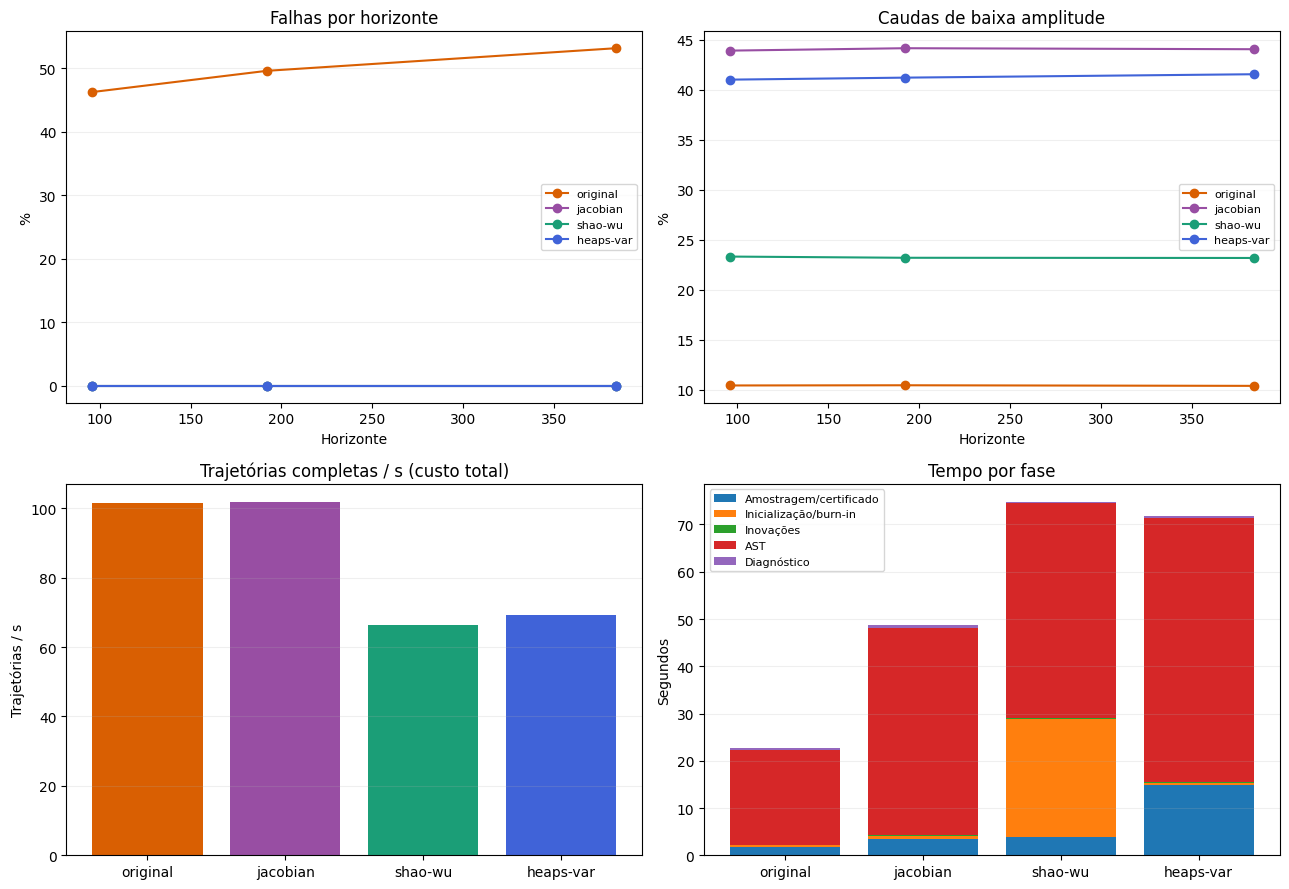

In [5]:
colors = {"original": "#d95f02", "jacobian": "#984ea3", "shao-wu": "#1b9e77", "heaps-var": "#4063d8"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for method in METHOD_ORDER:
    s = summary[summary.method.eq(method)]
    axes[0, 0].plot(s.horizon, 100*s.explosion_rate, marker="o", label=method, color=colors[method])
    axes[0, 1].plot(s.horizon, 100*s.near_zero_rate, marker="o", label=method, color=colors[method])
axes[0, 0].set(title="Falhas por horizonte", xlabel="Horizonte", ylabel="%")
axes[0, 1].set(title="Caudas de baixa amplitude", xlabel="Horizonte", ylabel="%")
p = performance.set_index("method").loc[METHOD_ORDER]
axes[1, 0].bar(METHOD_ORDER, p.successful_full_trajectories_per_second, color=list(colors.values()))
axes[1, 0].set(title="Trajetórias completas / s (custo total)", ylabel="Trajetórias / s")
bottom = np.zeros(len(METHOD_ORDER))
for key, label in [("sampling_and_certificate_seconds", "Amostragem/certificado"),
                   ("initialization_seconds", "Inicialização/burn-in"),
                   ("innovation_seconds", "Inovações"), ("ast_execution_seconds", "AST"),
                   ("diagnostic_seconds", "Diagnóstico")]:
    axes[1, 1].bar(METHOD_ORDER, p[key], bottom=bottom, label=label)
    bottom += p[key].to_numpy()
axes[1, 1].set(title="Tempo por fase", ylabel="Segundos")
for axis in axes.flat:
    axis.grid(alpha=.2, axis="y")
for axis in (axes[0, 0], axes[0, 1], axes[1, 1]):
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()


**O que foi feito.** Os gráficos mostram resultados por horizonte, velocidade total e custos por fase, incluindo o burn-in.

## Interpretação

Jacobiana certifica uma caixa invariante sob ruído limitado; Shao–Wu usa limites globais e inicialização aproximada com erro declarado; Heaps constrói VARs com histórico estacionário conjunto. Gaussianas podem ultrapassar limiares finitos mesmo em processos estacionários; por isso cruzamentos finitos e valores não finitos também são registrados.

Sementes locais por índice isolam a geração do RNG global do programa do usuário e da ordem dos jobs. Os testes correspondentes ficam em tests/unit/.

## Registro completo do experimento

In [6]:
def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=PROJECT_ROOT,
                                       text=True, stderr=subprocess.DEVNULL).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None

source_paths = [
    "src/tsfmxai/representations/expression.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/trajectory.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/evaluation/stability.py",
    "src/tsfmxai/evaluation/generator_tradeoff.py",
]
record = {
    "experiment_id": EXPERIMENT_ID, "status": "executed",
    "research_question": RESEARCH_QUESTION,
    "hypothesis": HYPOTHESIS,
    "configuration": configuration,
    "seed_policy": {
        "mechanisms": "derive_sample_seed(ROOT_SEED, index)",
        "benchmark_initialization_and_future_noise": "SeedSequence([ROOT_SEED, index, 991]).spawn(2)",
        "multiple_trajectories": "SeedSequence([root_seed, trajectory_index]).spawn(2)",
        "external_global_rng": False,
        "note": "Per-index local streams isolate generation from user RNG state and worker scheduling.",
    },
    "provenance": {
        "git_head": git_output("rev-parse", "HEAD"), "dirty_worktree": bool(git_output("status", "--porcelain")),
        "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest()
                          for name in source_paths},
        "python": sys.version, "platform": platform.platform(),
        "packages": {name: importlib.metadata.version(name)
                     for name in ("numpy", "pandas", "matplotlib", "joblib", "threadpoolctl")},
        "blas": threadpool_info(), "execution": "serial wall-clock; BLAS threads=1",
        "references": {"Shao-Wu": "https://arxiv.org/abs/math/0611029",
                       "Heaps": "https://arxiv.org/abs/2004.09455"},
    },
    "metrics": {"stability": json.loads(summary.to_json(orient="records")),
                "performance": json.loads(performance.to_json(orient="records")),
                "additional_checks": additional_checks},
    "scientific_summary": [
        f"{r.method}: h={r.horizon}, {r.explosions}/{r.N} threshold failures; "
        f"{r.near_zero}/{r.N} low-amplitude tails."
        for r in summary[summary.horizon.eq(max(HORIZONS))].itertuples()
    ],
    "limitations": [
        "near_zero means all final 24 values within +/-0.15, a finite-window low-amplitude label.",
        "Gaussian stationary samples may cross a finite threshold; threshold crossing and nonfinite outputs are recorded separately.",
        "One independent mechanism/realization per outcome denominator; Wilson intervals are over these samples.",
        "Families and native initialization/noise laws differ; matched variance does not make noise distributions identical.",
        "Shao-Wu initialization is approximate with a certified L2 coupling-error bound; Heaps uses a joint invariant Gaussian history.",
        "Single-run timings include failed attempts; they are hardware-dependent, without timing confidence intervals.",
        "The mathematical mappings are published; random AST construction and explanation-ready storage are project adaptations.",
    ],
    "reproduction_command": (
        ".\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        + NOTEBOOK_PATH + " --ExecutePreprocessor.timeout=3600"
    ),
}
print(json.dumps(record, indent=2, ensure_ascii=False))


{
  "experiment_id": "abstract_syntax_tree_006_four_current_methods",
  "status": "executed",
  "research_question": "Qual o trade-off entre falhas operacionais, baixa amplitude e custo dos quatro geradores?",
  "hypothesis": "Certificados reduzem falhas nas famílias admitidas, com custo de construção e inicialização.",
  "configuration": {
    "root_seed": 20261001,
    "count_per_method": 5000,
    "num_series": 1,
    "diagnostics": {
      "horizons": [
        96,
        192,
        384
      ],
      "explosion_limit": 100.0,
      "near_zero_radius": 0.15000000000000002,
      "near_zero_tail_steps": 24
    },
    "original": {
      "minimum_operators": 1,
      "maximum_operators": 6,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 12,
      "parameter_probability": 0.55,
      "time_probability": 0.0,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnitude": 0.8,
      "re

**O que foi feito.** O registro reúne configuração, sementes, hashes de fontes, métricas, limitações e reprodução no próprio notebook executado.